In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

In [2]:
def get_plot_group(model_name):
    # The order of this list is important. It checks for the most
    # specific keywords first before falling back to more general ones.
    group_keywords = [
        'SMOTE', 'Explainability Features', 'Xgboost Features',
        'StackedEnsemble_RF', 'Stacking', 'ResNet-CNN', 'ResNet-LSTM',
        'CNN-LSTM', 'Random Forest', 'MLP', 'XGBoost', 'Logistic Regression', 'LSTM', 'CNN'
    ]

    for keyword in group_keywords:
        if keyword in model_name:
            # Special case handling for 'XGBoost' to avoid confusion with 'Xgboost Features'.
            if keyword == 'XGBoost' and 'Xgboost Features' in model_name:
                continue
            return keyword

    # If no keyword is found, return a default 'Other' group.
    return 'Other'

In [3]:
# Data Loading
base_directory = os.path.join('..', '..')
path_2d = os.path.join(base_directory, '2D_Results.csv')
path_uav_attack = os.path.join(base_directory, 'UAVATTACK_Results.csv')

try:
    df_2d = pd.read_csv(path_2d)
    df_uav_attack = pd.read_csv(path_uav_attack)
    print("Successfully loaded '2D_Results.csv' and 'UAVATTACK_Results.csv'")
except FileNotFoundError as e:
    print(f"Error: Could not find a file. Make sure the path is correct.")
    print(f"File not found: {e.filename}")
    exit()

Successfully loaded '2D_Results_fixed.csv' and 'UAVATTACK_Results_fixed.csv'


In [4]:
# Data Preparation
df_2d['source_dataset'] = '2D'
df_uav_attack['source_dataset'] = 'UAV Attack'

# Combine the datasets.
combined_df = pd.concat([df_2d, df_uav_attack], ignore_index=True)

# Create the 'plot_group' column using our new grouping function.
combined_df['plot_group'] = combined_df['model'].apply(get_plot_group)

# Create cleaner labels for the y-axis.
combined_df['display_model'] = combined_df['model'].str.replace('Classifier', '') + ' (' + combined_df['source_dataset'] + ')'

# Reshape the DataFrame for plotting.
plot_df = combined_df.melt(
    id_vars=['display_model', 'plot_group'],
    value_vars=["mcc", "balanced_accuracy", "f1_macro", "g_mean", "accuracy"],
    var_name='Metric',
    value_name='Score'
)

Generating plot for the 'Logistic Regression' group...


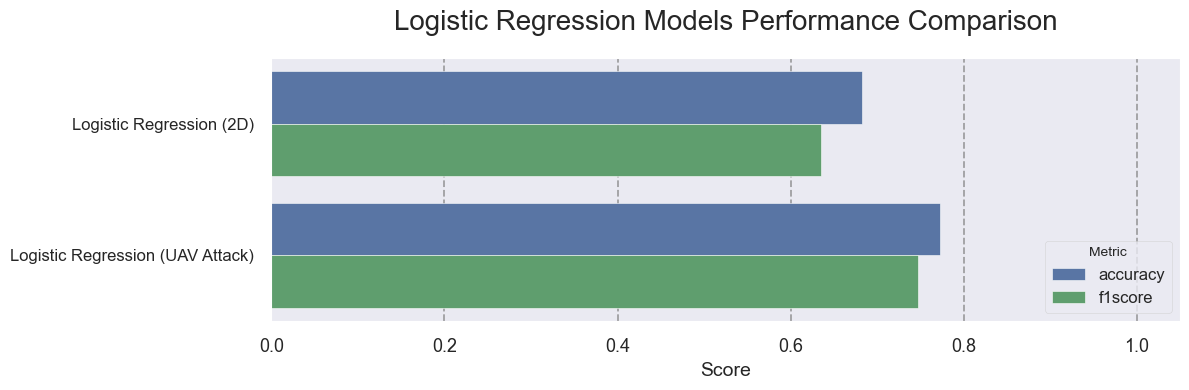

Saved chart to performance_chart_Logistic_Regression.png
Generating plot for the 'XGBoost' group...


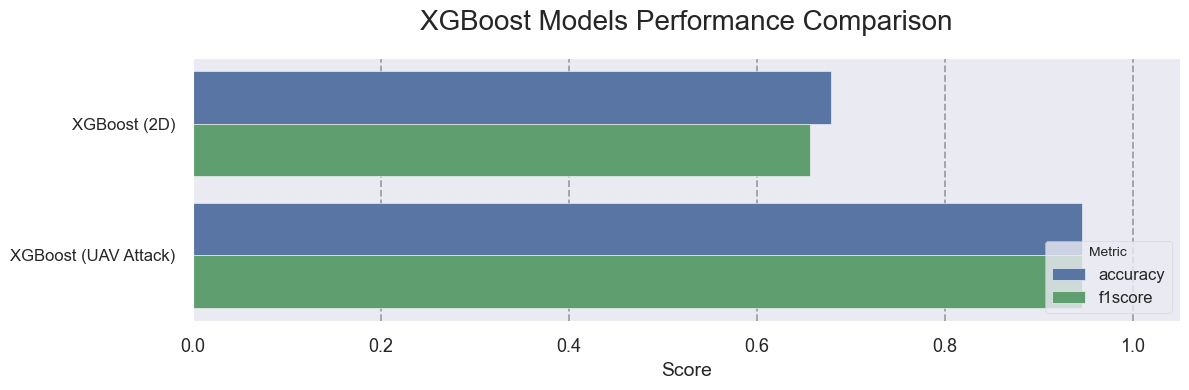

Saved chart to performance_chart_XGBoost.png
Generating plot for the 'MLP' group...


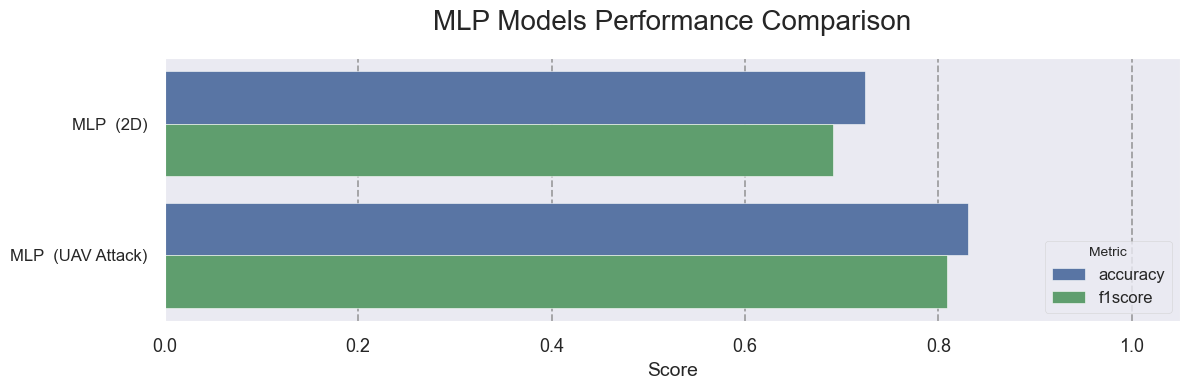

Saved chart to performance_chart_MLP.png
Generating plot for the 'Random Forest' group...


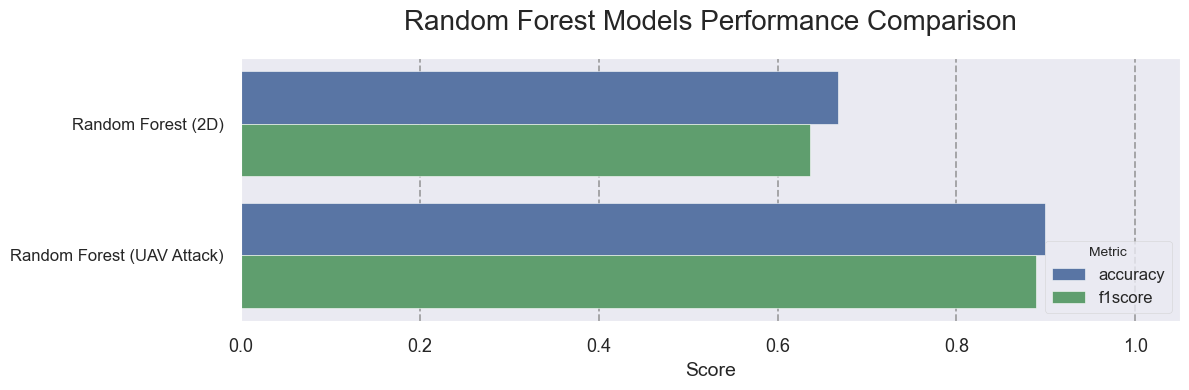

Saved chart to performance_chart_Random_Forest.png
Generating plot for the 'Stacking' group...


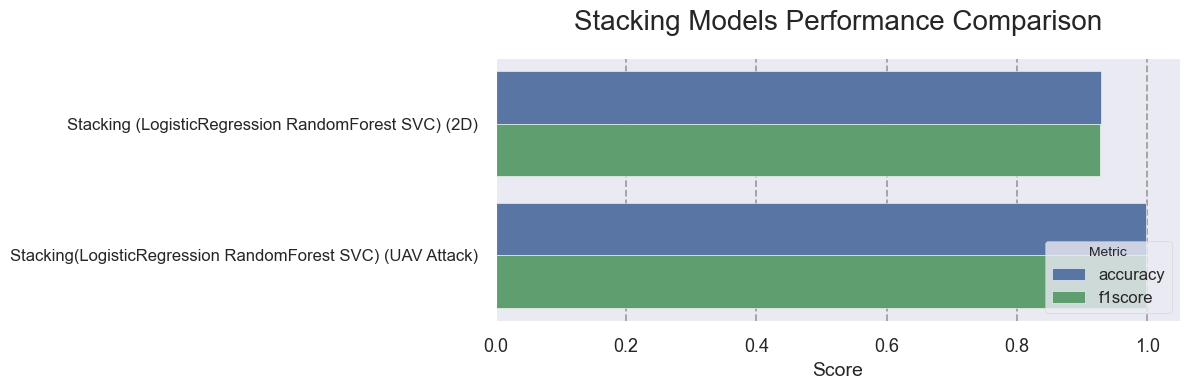

Saved chart to performance_chart_Stacking.png
Generating plot for the 'LSTM' group...


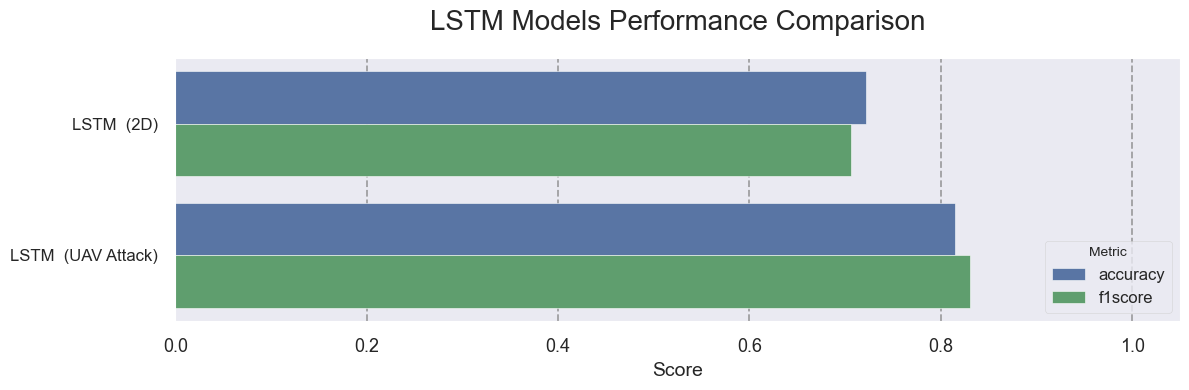

Saved chart to performance_chart_LSTM.png
Generating plot for the 'Explainability Features' group...


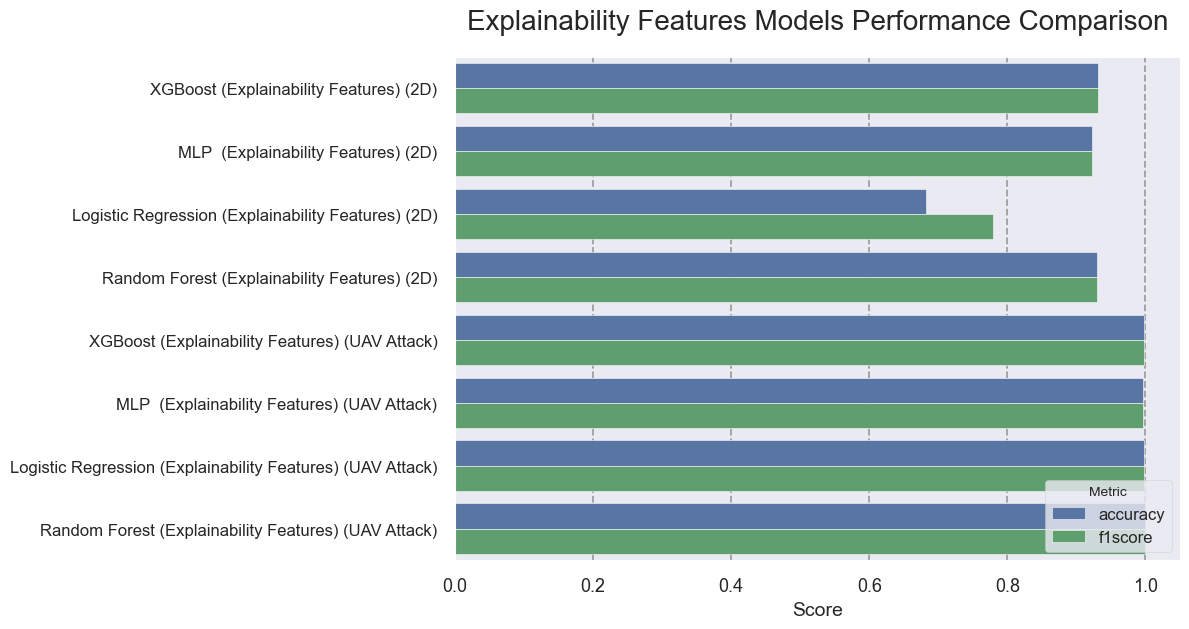

Saved chart to performance_chart_Explainability_Features.png
Generating plot for the 'Xgboost Features' group...


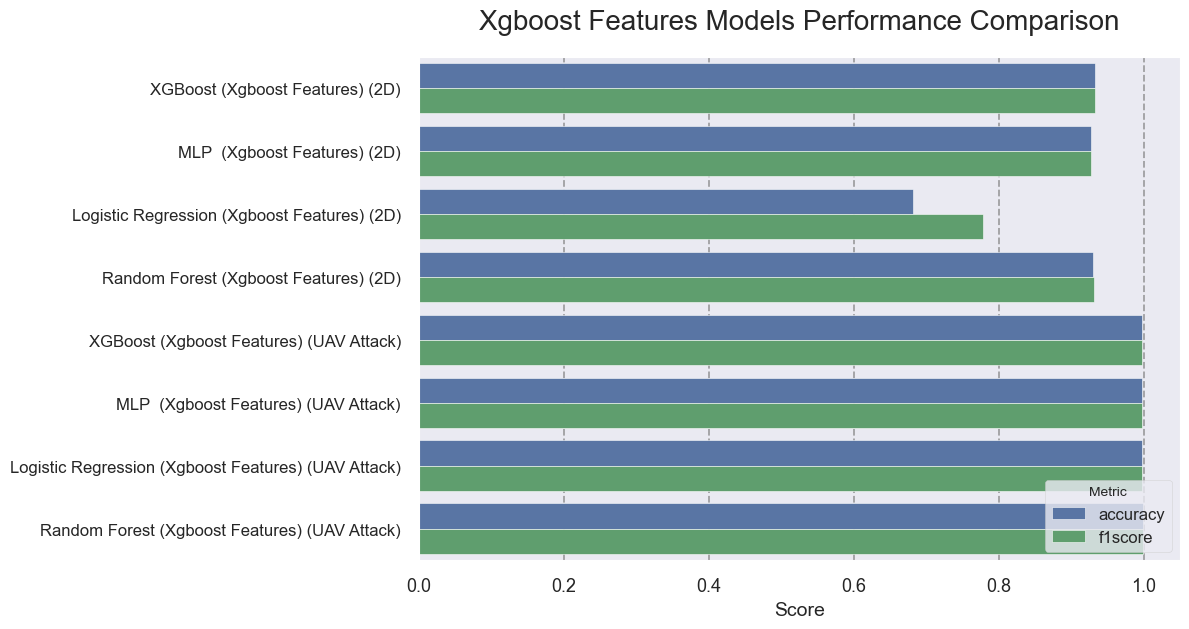

Saved chart to performance_chart_Xgboost_Features.png
Generating plot for the 'CNN' group...


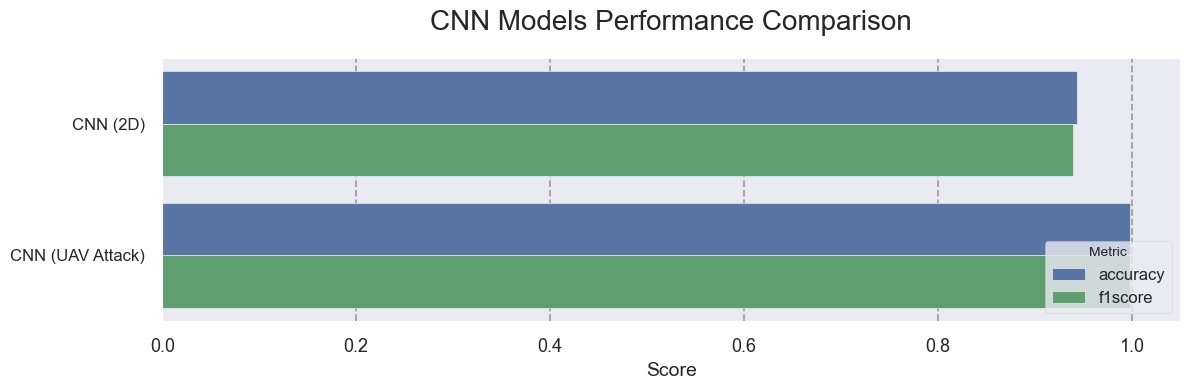

Saved chart to performance_chart_CNN.png
Generating plot for the 'StackedEnsemble_RF' group...


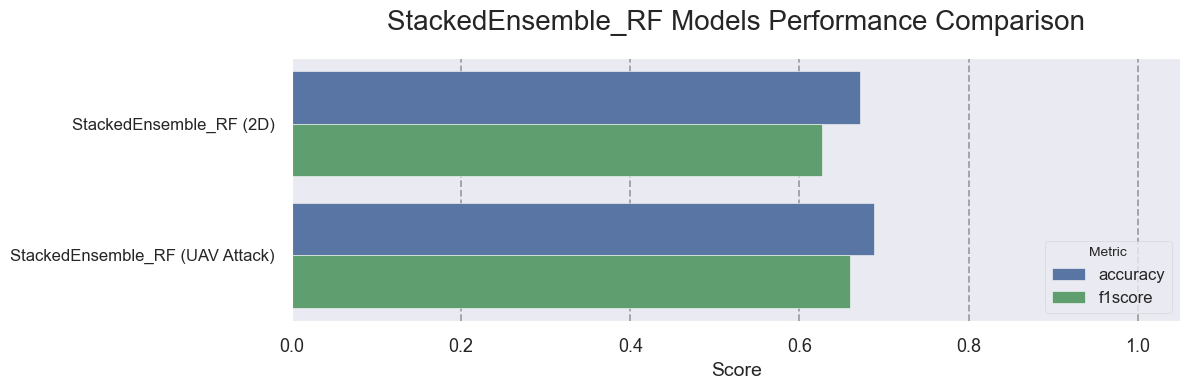

Saved chart to performance_chart_StackedEnsemble_RF.png
Generating plot for the 'CNN-LSTM' group...


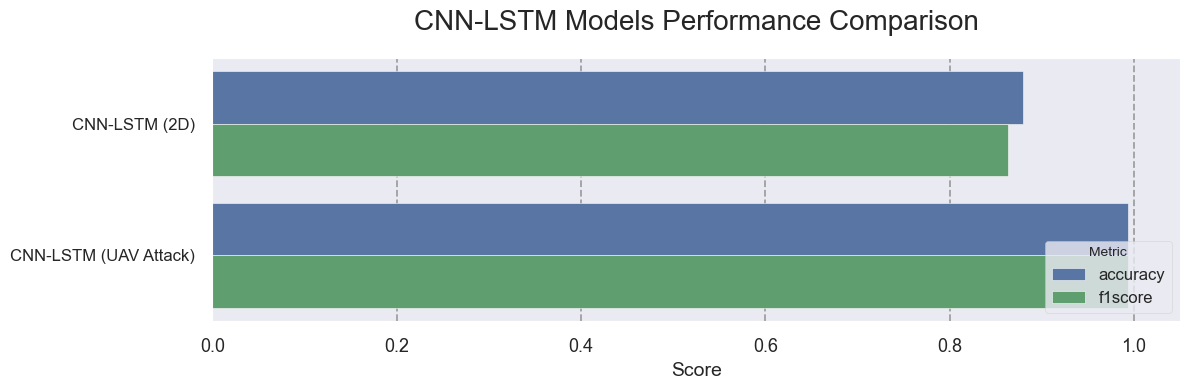

Saved chart to performance_chart_CNN-LSTM.png
Generating plot for the 'SMOTE' group...


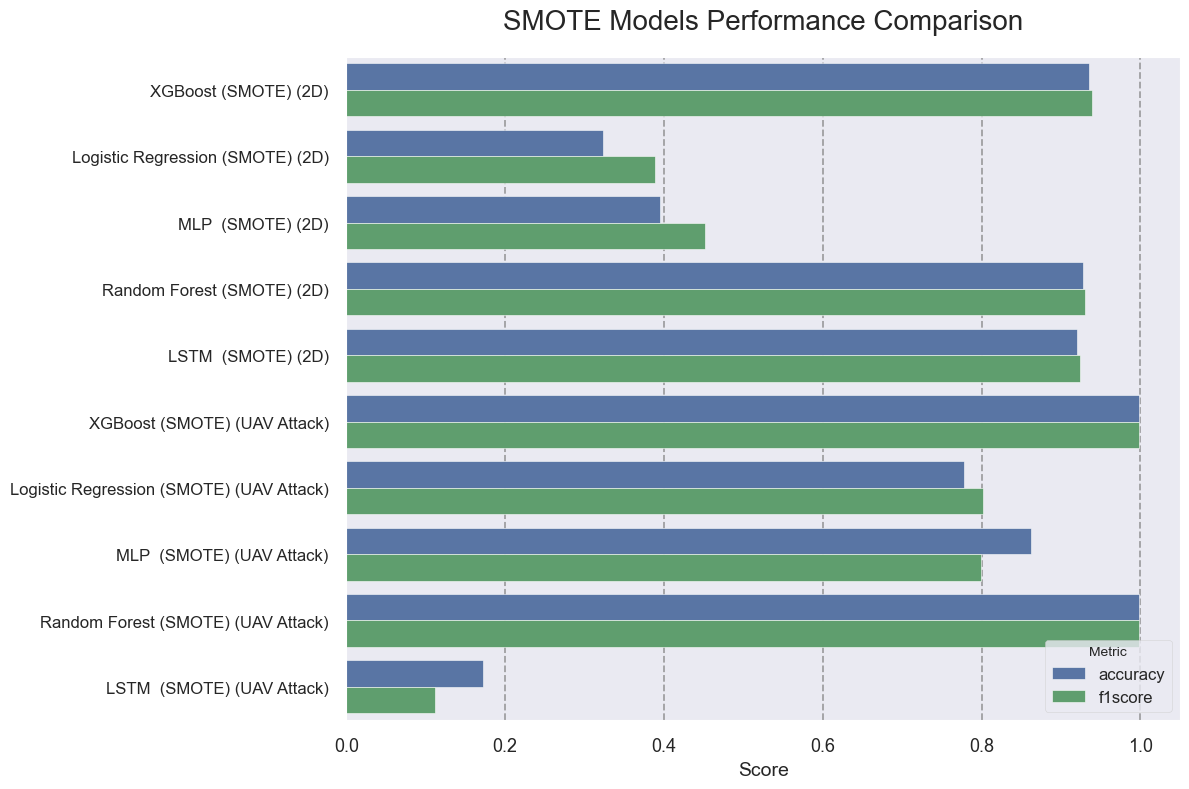

Saved chart to performance_chart_SMOTE.png
Generating plot for the 'ResNet-LSTM' group...


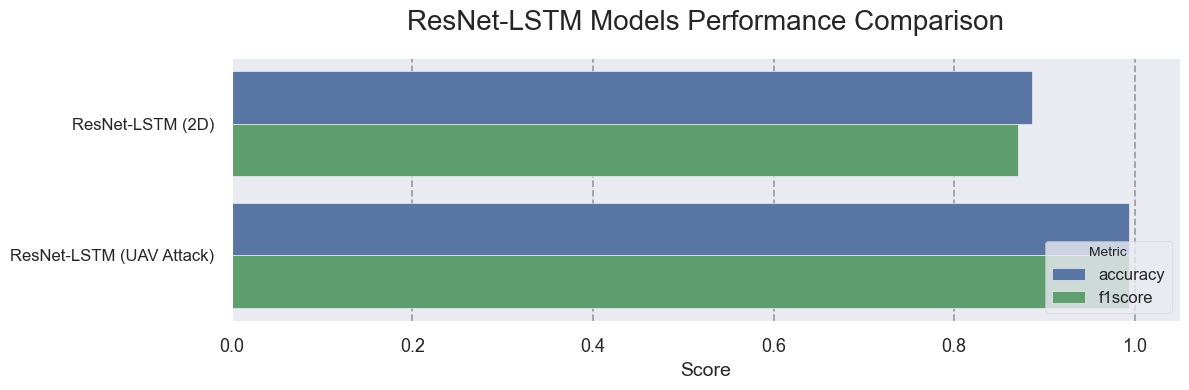

Saved chart to performance_chart_ResNet-LSTM.png
Generating plot for the 'ResNet-CNN' group...


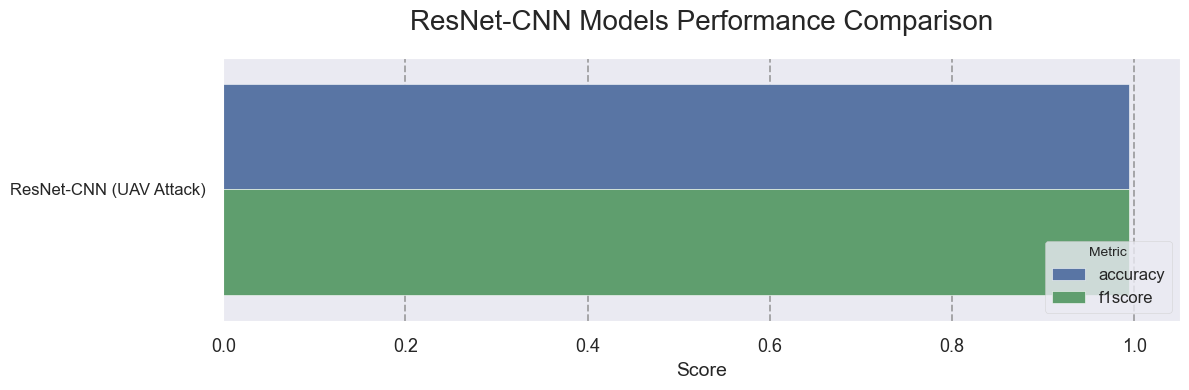

Saved chart to performance_chart_ResNet-CNN.png


In [5]:
# Visualization & Saving
model_groups = plot_df['plot_group'].unique()

for group in model_groups:
    print(f"Generating plot for the '{group}' group...")

    # Filter the data for the current group.
    group_df = plot_df[plot_df['plot_group'] == group]

    # Adjust the figure height based on the number of models in the group.
    num_bars = len(group_df['display_model'].unique())
    fig_height = max(4, num_bars * 0.8)

    plt.style.use('seaborn-v0_8-talk')
    plt.figure(figsize=(12, fig_height))

    # Create the horizontal bar plot.
    ax = sns.barplot(
        x='Score',
        y='display_model',
        hue='Metric',
        data=group_df,
        palette=['#3b4cc0', '#5d8fd1', '#7fb800', '#e08a1e', '#b0b0b0'],
        errorbar=None
    )

    # Add titles and labels.
    ax.set_title(f'{group} Models Performance Comparison', fontsize=20, pad=20)
    ax.set_xlabel('Score', fontsize=14)
    ax.set_ylabel('')
    ax.set_xlim(-0.05, 1.05)

    ax.xaxis.grid(True, linestyle='--', which='both', color='gray', alpha=0.7)
    ax.tick_params(axis='y', labelsize=12)
    plt.legend(title='Metric', loc='lower right', fontsize=12)

    plt.tight_layout()
    plt.show()
    # Save the plot to a file
    filename = f"performance_chart_{group.replace(' ', '_')}.png"
    plt.savefig(filename)
    print(f"Saved chart to {filename}")

    plt.close()